# 02 · CNN and morphological augmentation

紧凑 CNN：两层卷积 + ReLU + 池化 + 小型全连接层和 dropout。

只做一项对照：**几何增强 CNN** 与 **几何增强 + 形态学增强 CNN**。后者随机加入轻微腐蚀或膨胀，用来模拟笔画粗细变化。网络和其他训练设置保持一致；不预设增强一定有效。

先在 1,600/400 的训练内部划分上通过验证 loss 选择 epoch，再重新初始化模型，用全部 2,000 张训练图像训练选定轮数。测试集不用于早停或设置选择。

In [1]:
import os
import time
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from data_utils import load_data, get_trial, validation_indices, output_folder, SEED
from plot_utils import plot_training_split, plot_history
from evaluation import save_json, evaluate_predictions, save_method_summary, compare_methods
from cnn_utils import SimpleCNN, plot_augmentation, train_cnn, fit_full_training_set, predict_cnn, load_cnn_model

torch.set_num_threads(min(4, os.cpu_count() or 1))
config = {
    "seed": SEED,
    "device": "cpu",
    "batch_size": 64,
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "max_epochs": 25,
    "patience": 5,
    "morphology_probability": 0.35,
}
print("PyTorch:", torch.__version__, "Device:", config["device"])
print(SimpleCNN())
print("Parameters:", sum(p.numel() for p in SimpleCNN().parameters()))

PyTorch: 2.14.1+cpu Device: cpu
SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)
Parameters: 105866


## 1. 查看增强
只查看训练集样例。腐蚀／膨胀使用一次 3×3 十字形结构元素；不翻转数字，不反转极性，验证和测试都不增强。

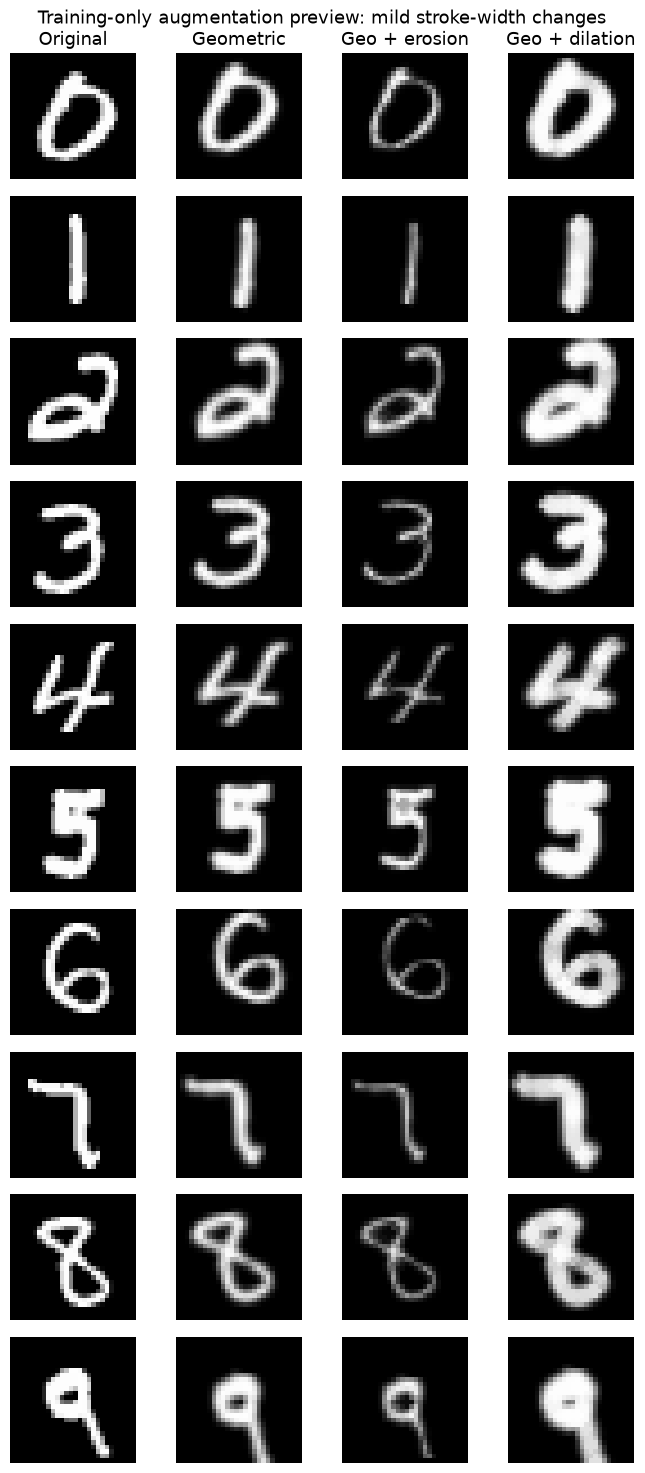

In [2]:
data = load_data()
X_train, y_train, _, _ = get_trial(data, 1)
plot_augmentation(X_train, y_train, output_folder("cnn_morphology"), seed=SEED)

## 2. 执行两个 trial 和一项增强对照

默认最多 25 个 epoch。`history.csv` 每个 epoch 更新，记录训练／验证 loss、准确率、累计耗时；最佳验证模型和最终模型分别保存。

训练准确率在启用 dropout 和增强时计算，验证准确率在关闭 dropout、无增强时计算。最终训练曲线没有验证集，因为该阶段使用全部 2,000 张训练图像。不要把最终训练 loss 当成验证 loss。

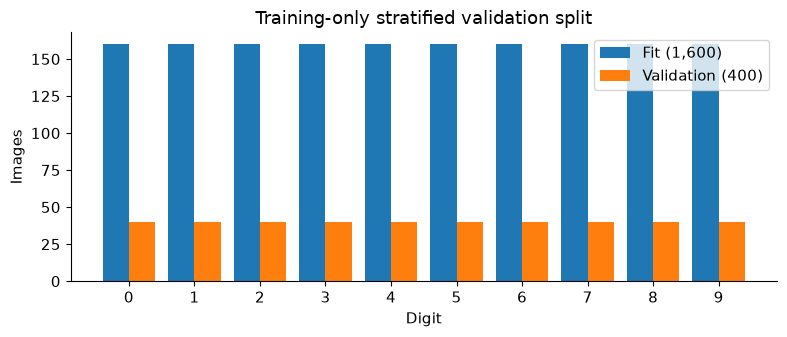


 CNN geometric Trial 1


Epoch 01: loss 2.2115/1.9124, accuracy 0.203/0.520


Epoch 02: loss 1.7445/1.0941, accuracy 0.419/0.677


Epoch 03: loss 1.2828/0.6714, accuracy 0.570/0.807


Epoch 04: loss 1.0615/0.5235, accuracy 0.638/0.850


Epoch 05: loss 0.9368/0.4137, accuracy 0.679/0.900


... (16 outputs left out)

Epoch 22: loss 0.3370/0.0912, accuracy 0.890/0.970


Epoch 23: loss 0.3115/0.0737, accuracy 0.898/0.973


Epoch 24: loss 0.2762/0.0640, accuracy 0.913/0.983


Epoch 25: loss 0.3033/0.0873, accuracy 0.908/0.975


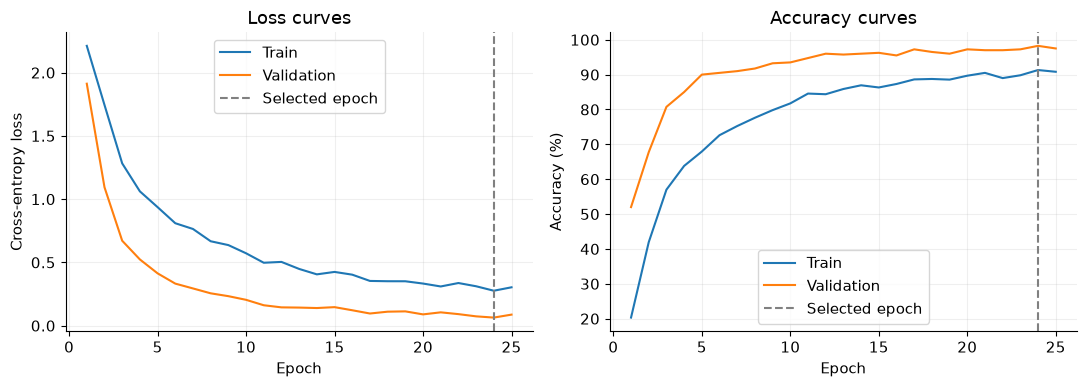

Final fit on all 2,000 training images; selected epochs: 24


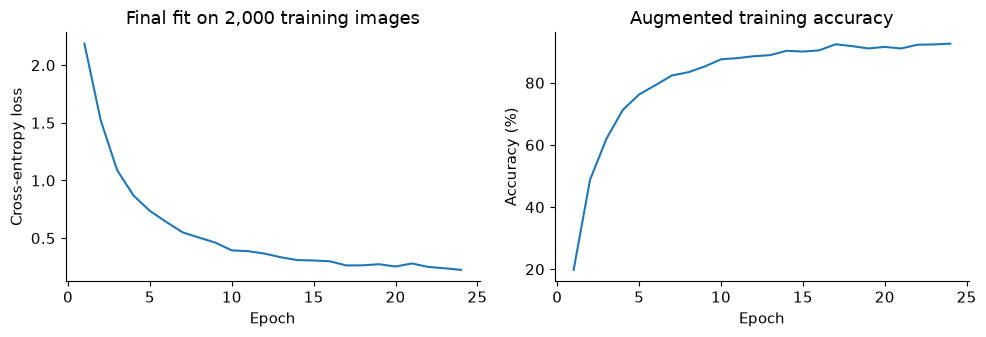

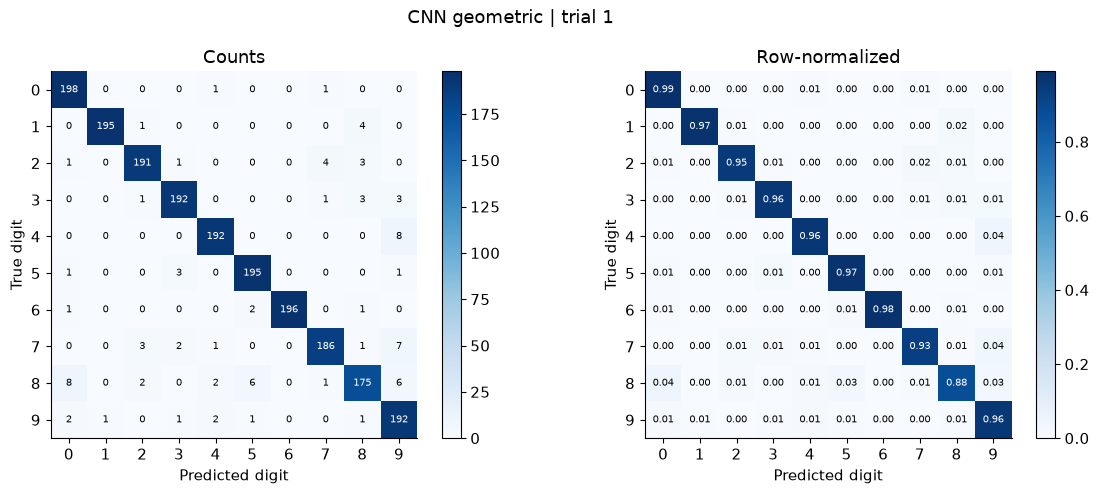

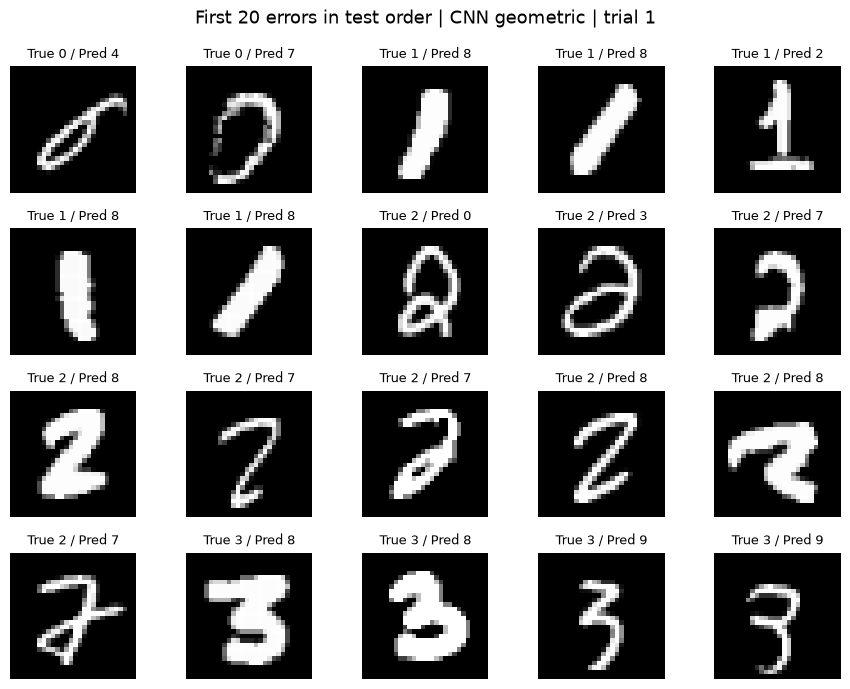

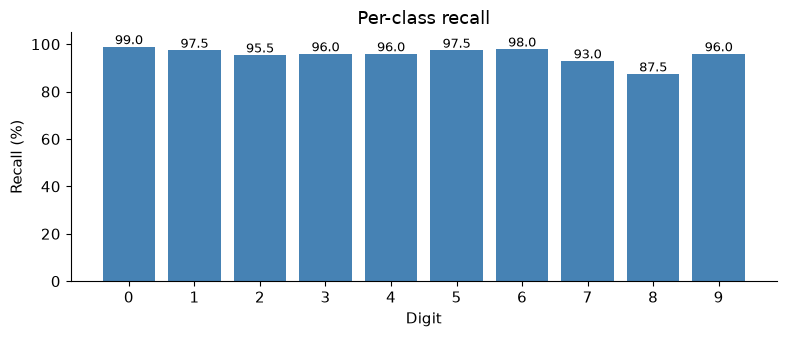

CNN geometric trial 1 accuracy = 0.9560


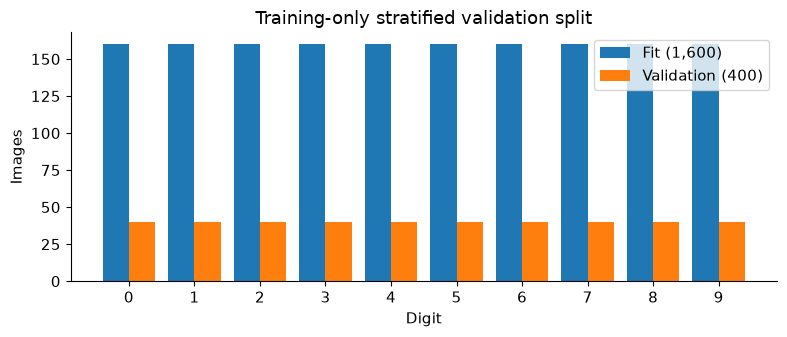


 CNN geometric Trial 2


Epoch 01: loss 2.1898/1.8000, accuracy 0.208/0.505


Epoch 02: loss 1.5717/0.8819, accuracy 0.511/0.725


Epoch 03: loss 1.1620/0.6385, accuracy 0.599/0.802


Epoch 04: loss 0.9521/0.5181, accuracy 0.671/0.818


Epoch 05: loss 0.8113/0.3824, accuracy 0.729/0.885


... (16 outputs left out)

Epoch 22: loss 0.2227/0.1174, accuracy 0.932/0.958


Epoch 23: loss 0.2251/0.1447, accuracy 0.928/0.953


Epoch 24: loss 0.2385/0.1327, accuracy 0.921/0.958


Epoch 25: loss 0.2071/0.1091, accuracy 0.932/0.960


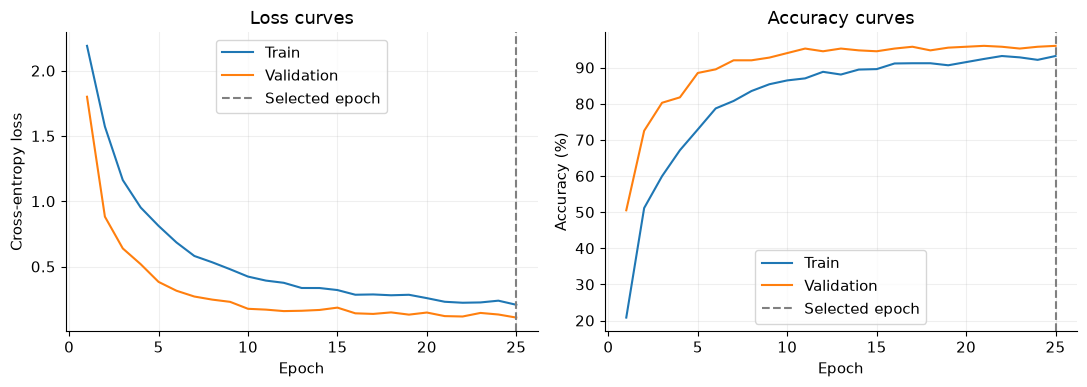

Final fit on all 2,000 training images; selected epochs: 25


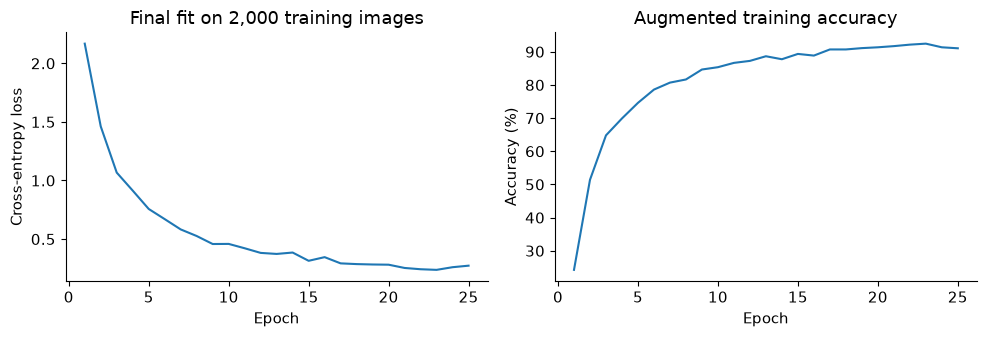

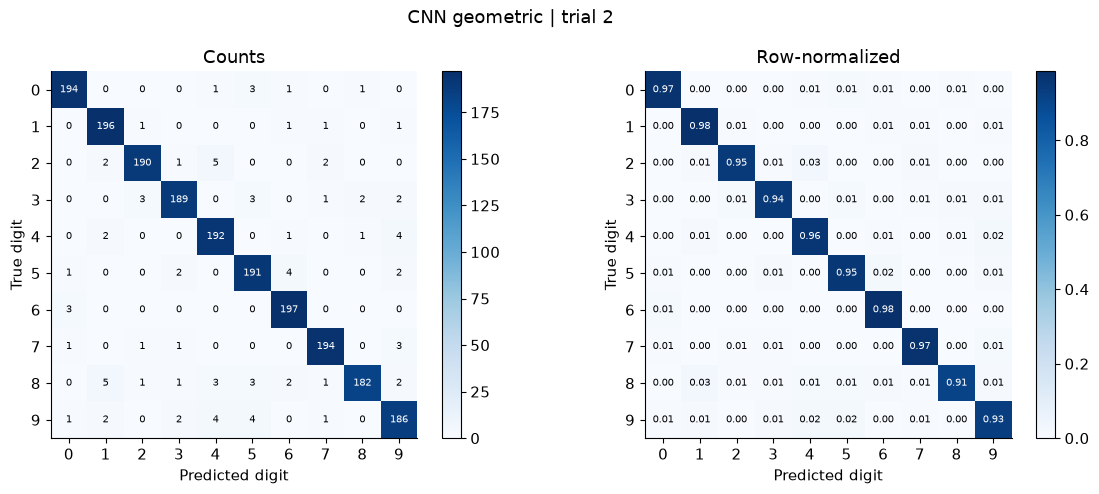

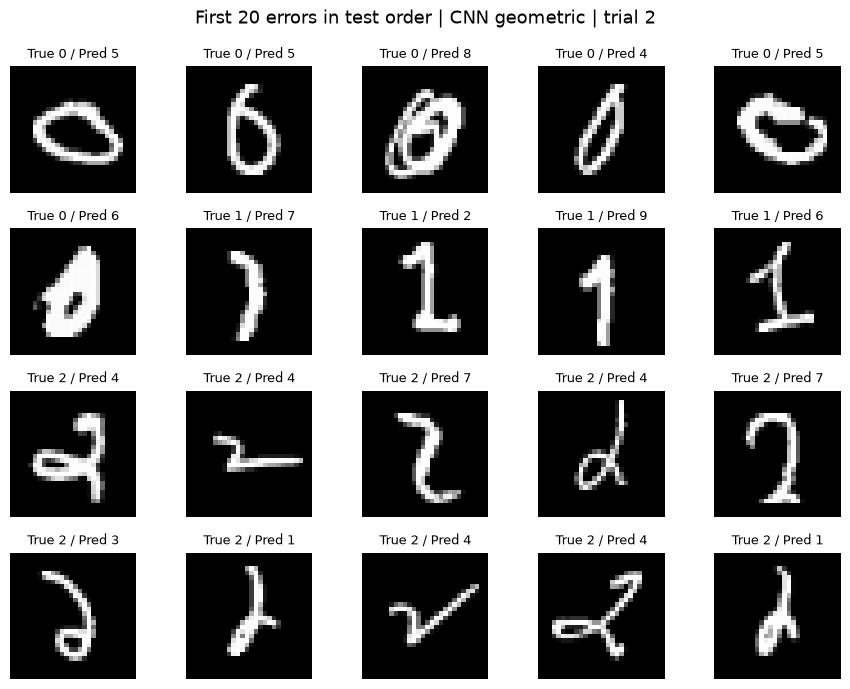

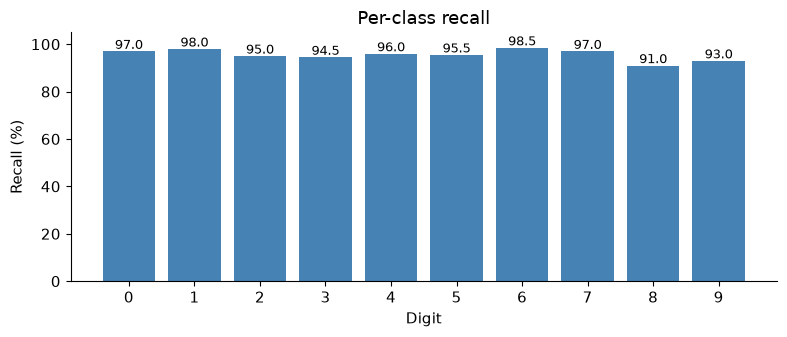

CNN geometric trial 2 accuracy = 0.9555


,method,mean_accuracy,std_accuracy,mean_macro_f1,mean_train_seconds,mean_predict_seconds
0,CNN geometric,0.95575,0.000354,0.955727,42.834622,0.265899


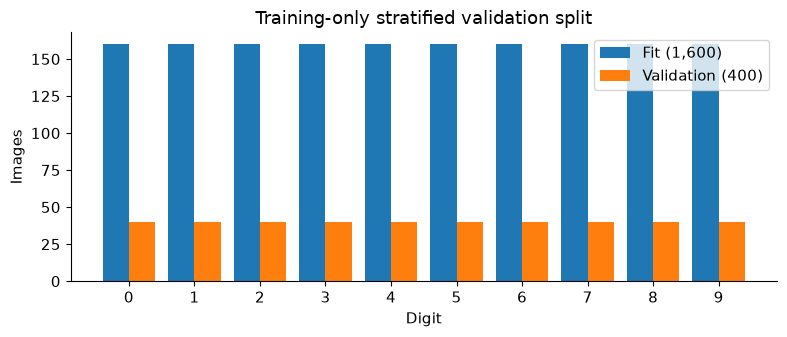


 CNN + morphology Trial 1


Epoch 01: loss 2.2331/1.9759, accuracy 0.181/0.385


Epoch 02: loss 1.8288/1.1632, accuracy 0.381/0.725


Epoch 03: loss 1.4197/0.8283, accuracy 0.528/0.775


Epoch 04: loss 1.1826/0.5718, accuracy 0.598/0.845


Epoch 05: loss 1.0433/0.4614, accuracy 0.656/0.863


... (16 outputs left out)

Epoch 22: loss 0.4056/0.0955, accuracy 0.877/0.975


Epoch 23: loss 0.3851/0.0834, accuracy 0.876/0.968


Epoch 24: loss 0.3563/0.0720, accuracy 0.888/0.978


Epoch 25: loss 0.3618/0.0950, accuracy 0.889/0.970


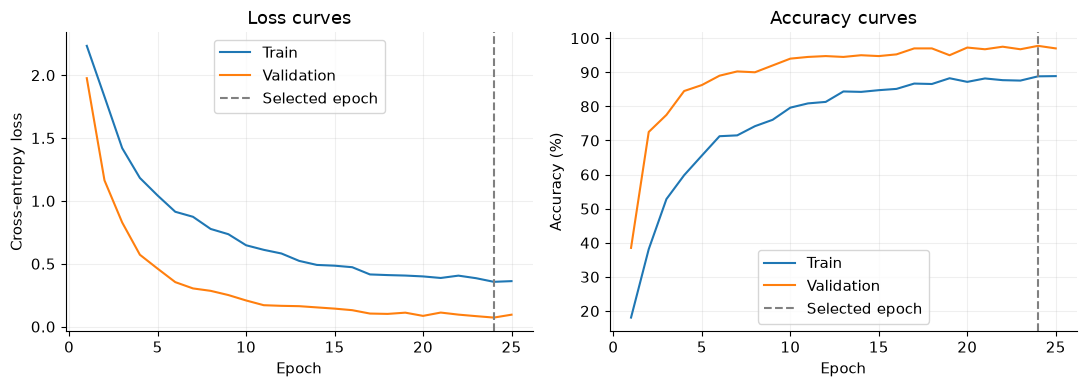

Final fit on all 2,000 training images; selected epochs: 24


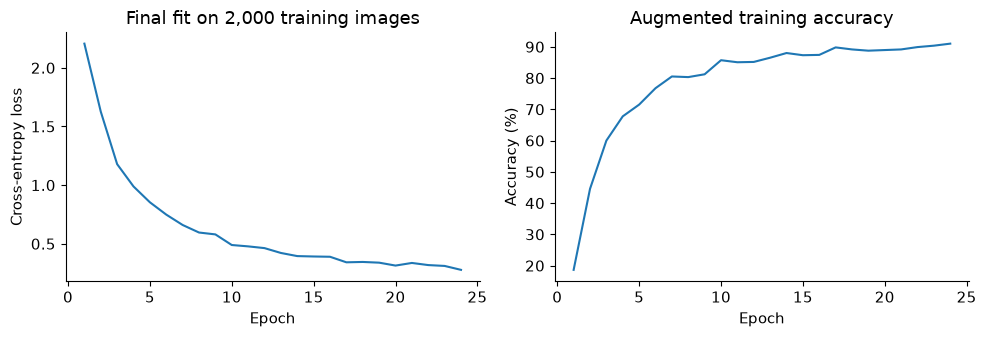

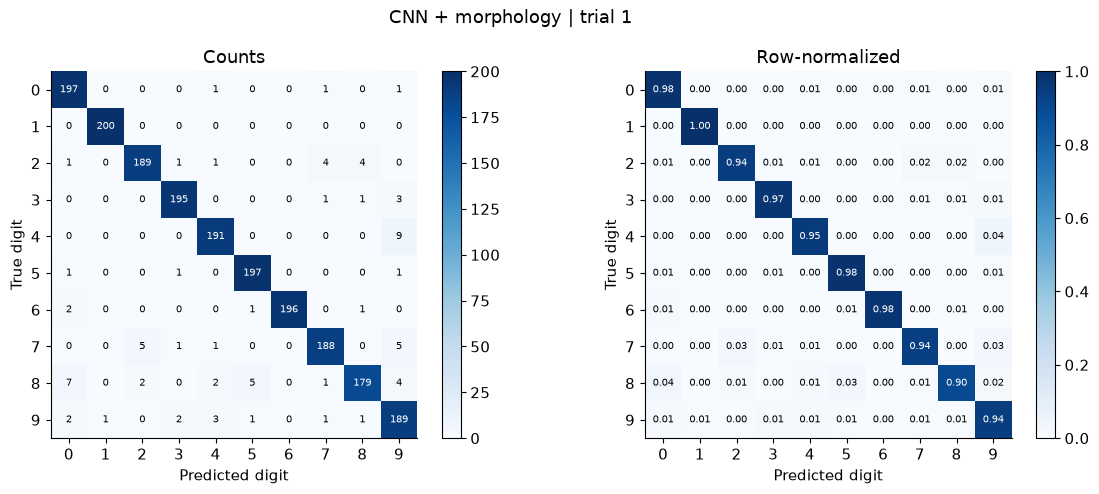

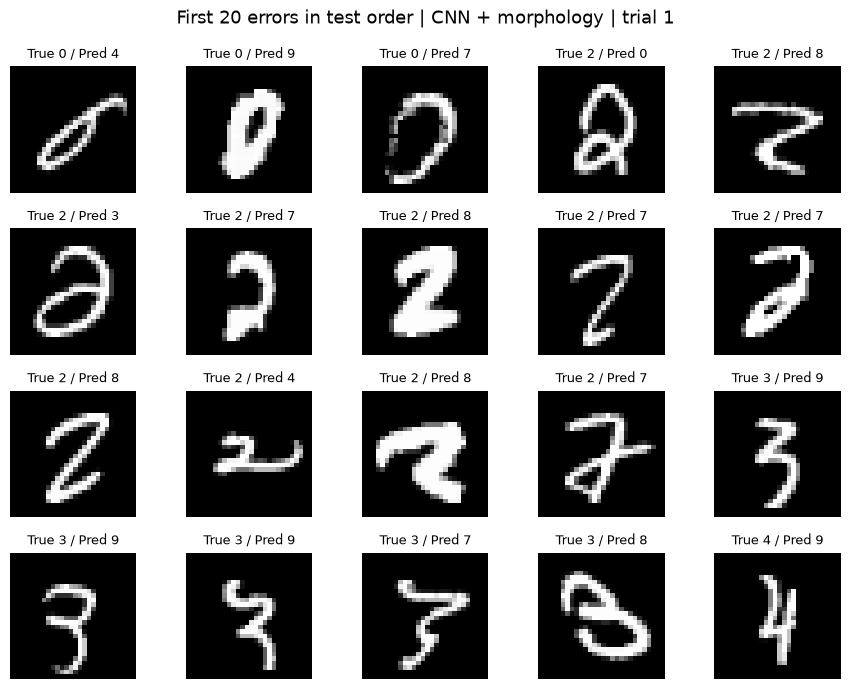

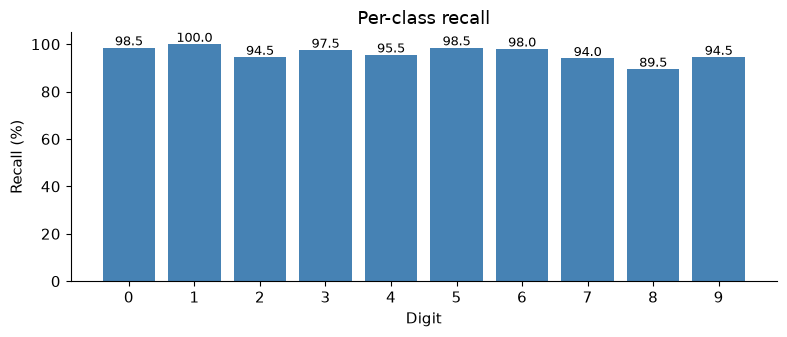

CNN + morphology trial 1 accuracy = 0.9605


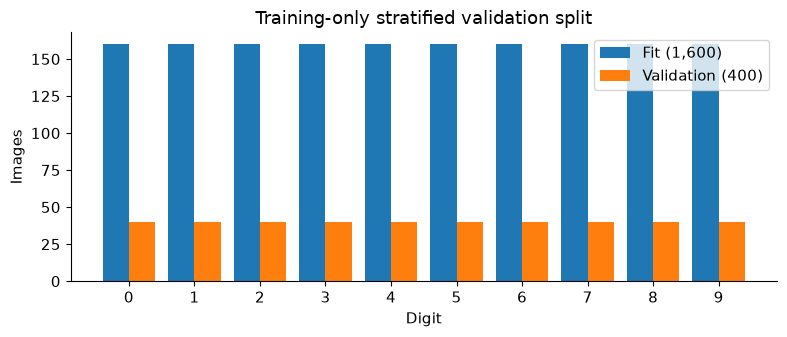


 CNN + morphology Trial 2


Epoch 01: loss 2.2089/1.8603, accuracy 0.204/0.487


Epoch 02: loss 1.6883/0.9503, accuracy 0.468/0.693


Epoch 03: loss 1.3104/0.6726, accuracy 0.556/0.775


Epoch 04: loss 1.0675/0.5210, accuracy 0.634/0.833


Epoch 05: loss 0.9159/0.3782, accuracy 0.700/0.887


... (16 outputs left out)

Epoch 22: loss 0.2820/0.1166, accuracy 0.913/0.960


Epoch 23: loss 0.2781/0.1369, accuracy 0.918/0.948


Epoch 24: loss 0.2782/0.1259, accuracy 0.913/0.955


Epoch 25: loss 0.2646/0.1026, accuracy 0.916/0.960


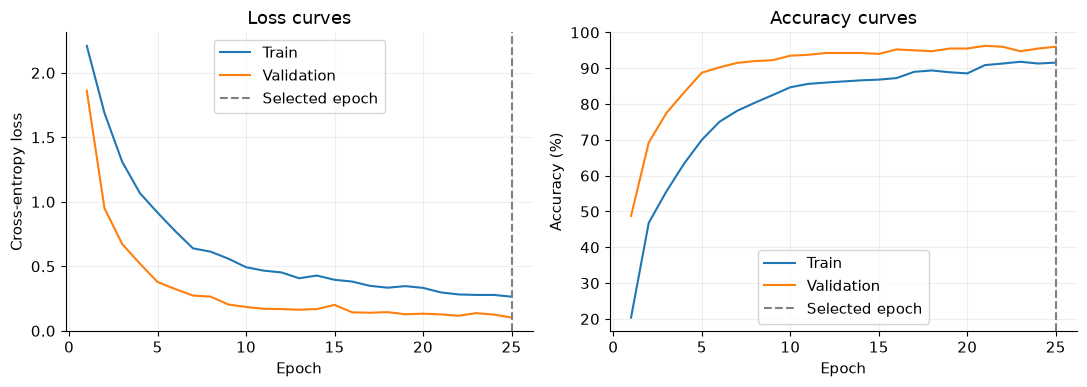

Final fit on all 2,000 training images; selected epochs: 25


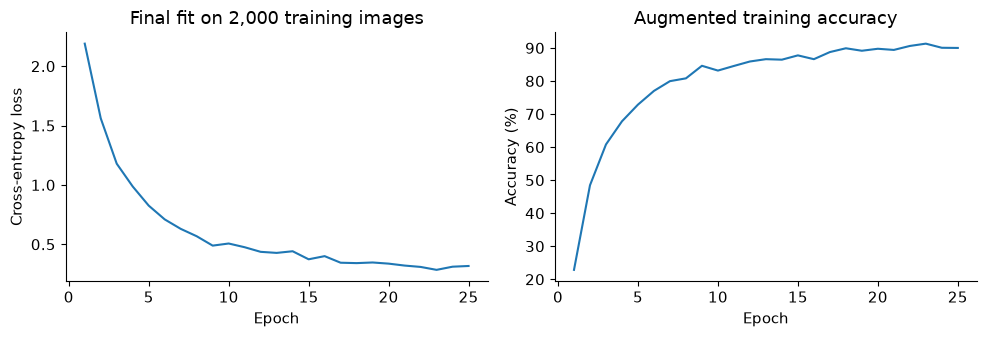

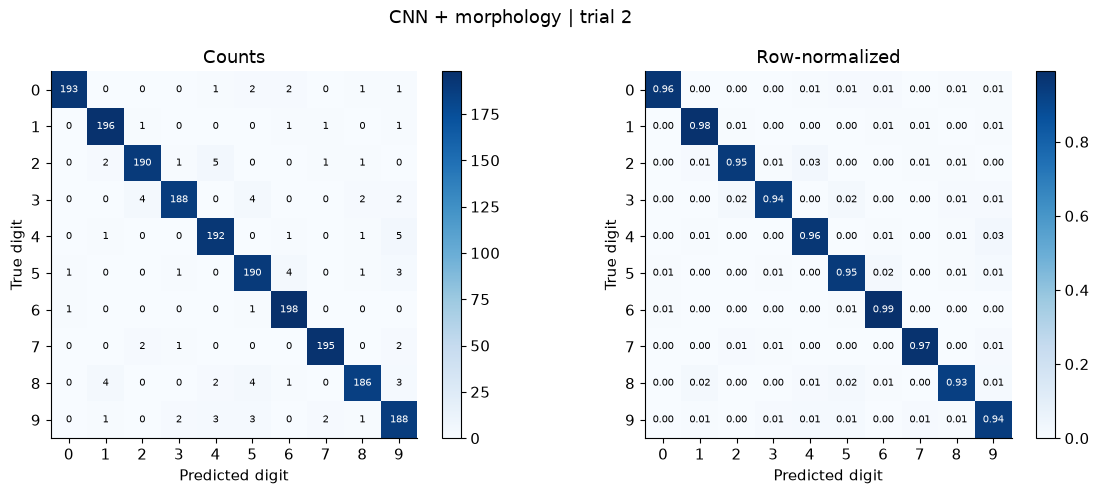

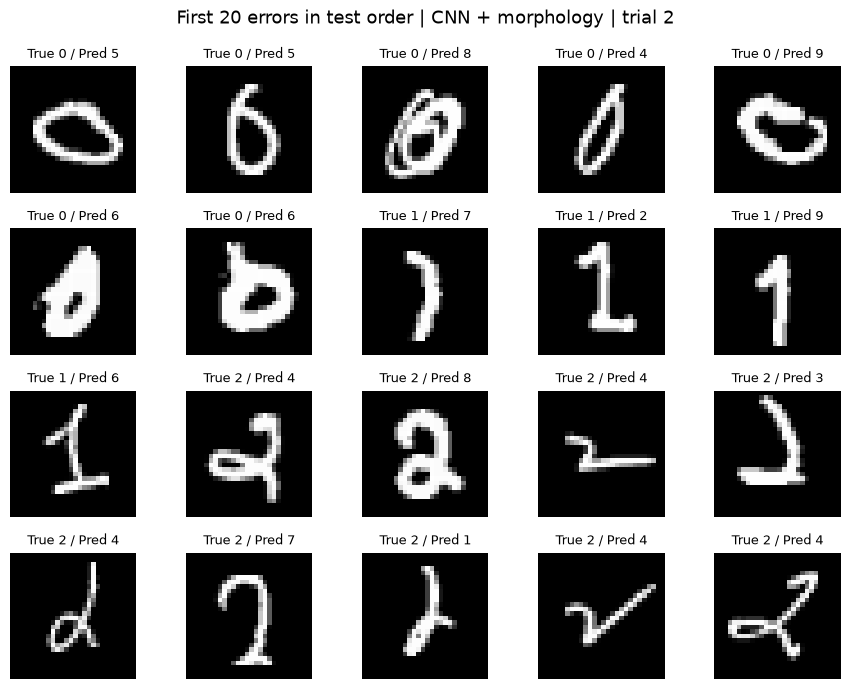

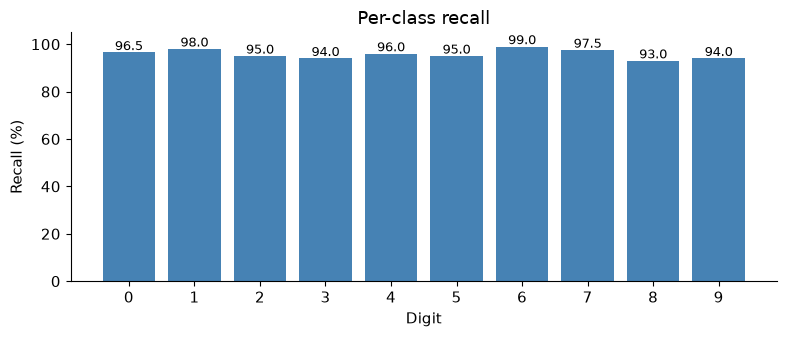

CNN + morphology trial 2 accuracy = 0.9580


,method,mean_accuracy,std_accuracy,mean_macro_f1,mean_train_seconds,mean_predict_seconds
0,CNN + morphology,0.95925,0.001768,0.959263,46.743297,0.257345


In [3]:
all_rows = []
settings = [("cnn_geometric", "CNN geometric", False),
            ("cnn_morphology", "CNN + morphology", True)]

for method_key, method_name, use_morphology in settings:
    method_rows = []
    for trial in [1, 2]:
        folder = output_folder(method_key, trial)
        X_train, y_train, X_test, y_test = get_trial(data, trial)
        fit, val = validation_indices(y_train, seed=SEED)
        trial_config = config.copy()
        trial_config["seed"] = SEED + trial
        save_json({**trial_config, "trial": trial, "use_morphology": use_morphology,
                   "validation_fraction": 0.2, "split_seed": SEED}, folder / "config.json")
        np.savez(folder / "validation_indices.npz", fit=fit, validation=val,
                 original_train_indices=data["train_indices"][trial - 1])
        plot_training_split(y_train, fit, val, folder)

        print("\n", method_name, "Trial", trial)
        start = time.perf_counter()
        selected_model, history, best_epoch = train_cnn(
            X_train[fit], y_train[fit], X_train[val], y_train[val],
            trial_config, use_morphology, folder)
        selection_seconds = time.perf_counter() - start
        plot_history(history, folder)

        print("Final fit on all 2,000 training images; selected epochs:", best_epoch)
        start = time.perf_counter()
        model = fit_full_training_set(X_train, y_train, trial_config, use_morphology, best_epoch, folder)
        final_fit_seconds = time.perf_counter() - start
        save_json({"best_epoch": best_epoch, "best_validation_loss": float(history["val_loss"].min()),
                   "selection_seconds": selection_seconds, "final_fit_seconds": final_fit_seconds},
                  folder / "training_selection.json")

        start = time.perf_counter()
        predictions, probabilities = predict_cnn(model, X_test, trial_config)
        predict_seconds = time.perf_counter() - start
        metrics = evaluate_predictions(
            y_test, predictions, X_test, folder, method_name, trial,
            selection_seconds + final_fit_seconds, predict_seconds,
            sample_indices=data["test_indices"][trial - 1], probabilities=probabilities)
        method_rows.append(metrics)
        all_rows.append(metrics)
    display(save_method_summary(method_rows, output_folder(method_key)))

## 3. 汇总和增强收益
增强收益是同一 trial 中两种设置的准确率差，单位为百分点。单个随机种子的差异只作观察，不声称统计显著。

,method,trial,n_test,accuracy,macro_f1,train_seconds,predict_seconds
0,CNN geometric,1,2000,0.9560,0.956012,44.649663,0.289626
1,CNN geometric,2,2000,0.9555,0.955443,41.019580,0.242172
2,CNN + morphology,1,2000,0.9605,0.960500,48.450704,0.277286
3,CNN + morphology,2,2000,0.9580,0.958026,45.035890,0.237404


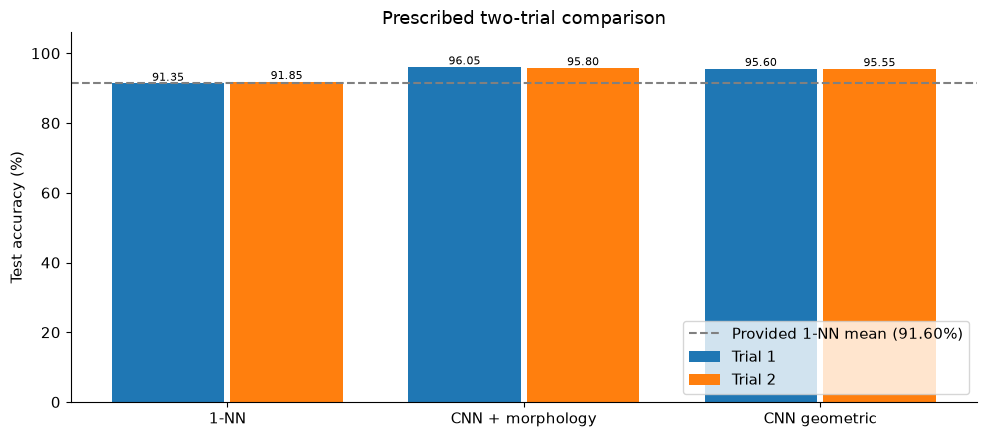

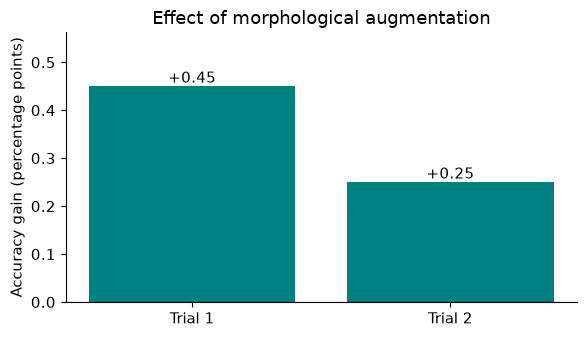

,method,mean_accuracy,std_accuracy,mean_macro_f1,mean_train_seconds,mean_predict_seconds
0,1-NN,0.91600,0.003536,0.915482,0.022998,0.132497
1,CNN + morphology,0.95925,0.001768,0.959263,46.743297,0.257345
2,CNN geometric,0.95575,0.000354,0.955727,42.834622,0.265899


In [4]:
display(pd.DataFrame(all_rows))
display(compare_methods())

## 4. 加载模型用于附加挑战

整理好 `new_images` 后使用下列接口；最终模型选择遵守老师的挑战规则：

```python
model, saved_config = load_cnn_model(output_folder("cnn_morphology", 1) / "final_model.pt")
new_predictions, new_probabilities = predict_cnn(model, new_images, saved_config)
```

检查 `results/cnn_geometric/` 和 `results/cnn_morphology/` 中的配置、CSV、模型和 PNG/PDF。不要只保留截图而丢失原始数值。